# RT-IoT2022 - One-Class SVM (Support Vector Machine)

Now we are going to apply the One-Class SVM algorithm to our dataset. The main steps are:

- load the preprocessed datasets
- train a baseline One-Class SVM using default hyperparameters
- evaluate the model on the validation set
- study the effect of 'nu' and 'gamma'
- select the best configuration using validation
- evaluate the selected model on the untouched test set
- analyze the detection rate for the different attack types

The model is trained only on normal IoT traffic.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)



In [24]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

train_metadata = pd.read_csv("../data/processed/train_metadata.csv")
val_metadata = pd.read_csv("../data/processed/val_metadata.csv")
test_metadata = pd.read_csv("../data/processed/test_metadata.csv")

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (7209, 92)
Validation set: (55356, 92)
Test set: (55357, 92)


In [25]:
y_val = (val_metadata["Label"] == "Anomaly").astype(int)
y_test = (test_metadata["Label"] == "Anomaly").astype(int)

print("Validation labels:")
print(y_val.value_counts())

print("\nTest labels:")
print(y_test.value_counts())

Validation labels:
Label
1    52953
0     2403
Name: count, dtype: int64

Test labels:
Label
1    52954
0     2403
Name: count, dtype: int64


In [26]:
baseline_model = OneClassSVM()
baseline_model.fit(X_train)
baseline_predictions = baseline_model.predict(X_val)

baseline_predictions = (baseline_predictions == -1).astype(int)

In [27]:
cm = confusion_matrix(y_val, baseline_predictions)
print(cm)

[[ 1227  1176]
 [   42 52911]]


In [28]:
tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positivess:", fp)
print("False negatives:", fn)
print("True positives:", tp)


True negatives: 1227
False positivess: 1176
False negatives: 42
True positives: 52911


In [29]:
accuracy = accuracy_score(y_val, baseline_predictions)
precision = precision_score(y_val, baseline_predictions)
recall = recall_score(y_val, baseline_predictions)
f1 = f1_score(y_val, baseline_predictions)
balanced_accuracy = balanced_accuracy_score(y_val, baseline_predictions)

fpr = fp / (fp + tn)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("Balanced Accuracy:", balanced_accuracy)
print("False Positive Rate:", fpr)


Accuracy: 0.9779969650986343
Precision: 0.9782572522047812
Recall: 0.9992068438048836
F1-score: 0.9886210762331838
Balanced Accuracy: 0.75490928956786
False Positive Rate: 0.4893882646691635


In [30]:
baseline_scores = -baseline_model.decision_function(X_val)

roc_auc = roc_auc_score(y_val, baseline_scores)
pr_auc = average_precision_score(y_val, baseline_scores)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.985978638442547
PR-AUC: 0.9993313079720296


## Hyperparameter analysis - parameter 'nu'

The 'nu' parameter is very important because it influences the One-Class SVM boundary decision. A larger nu generally allows more training observations to fall outside the learned normal region and viceversa for a smaller nu.

The default value is '0.5', but this value SHOULD NOT be accepted without analysis because the training dataset should contain ONLY normal traffic.

## Hyperparameter analysis - parameter 'gamma'

The RBF kernel is used to learn a non-linear boundary around normal traffic. 

The goal of the 'gamma' parameter is to control how strongly individual training samples influence the shape of this boundary.

So, small gamma values tend to produce smoother boundaries while larger values can create more complex and local boundaries.

In this project, both nu and gamma are analyzed instead of simply using their default values.

In [31]:
nu_values = [0.01, 0.05, 0.10, 0.20, 0.50]
gamma_values = ["scale", 0.001, 0.01, 0.1]

In [32]:
results = []

for nu in nu_values:
    for gamma in gamma_values:
        
        print("Testing nu =", nu, "gamma =", gamma)
        
        model = OneClassSVM(
            kernel = "rbf",
            nu = nu,
            gamma = gamma  
        )
        
        model.fit(X_train)
        
        predictions = model.predict(X_val)
        predictions = (predictions == -1).astype(int)
        
        cm = confusion_matrix(y_val, predictions)
        tn, fp, fn, tp = cm.ravel()
        
        precision = precision_score(y_val, predictions)
        recall = recall_score(y_val, predictions)
        f1 = f1_score(y_val, predictions)
        balanced_accuracy = balanced_accuracy_score(
            y_val,
            predictions
        )
        
        fpr = fp / (fp + tn)
        
        scores = -model.decision_function(X_val)
        
        roc_auc = roc_auc_score(y_val, scores)
        pr_auc = average_precision_score(y_val, scores)
        
        results.append({
            "nu": nu,
            "gamma": gamma,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "balanced_accuracy": balanced_accuracy,
            "fpr": fpr,
            "roc_auc": roc_auc,
            "pr_auc": pr_auc
        })

Testing nu = 0.01 gamma = scale
Testing nu = 0.01 gamma = 0.001
Testing nu = 0.01 gamma = 0.01
Testing nu = 0.01 gamma = 0.1
Testing nu = 0.05 gamma = scale
Testing nu = 0.05 gamma = 0.001
Testing nu = 0.05 gamma = 0.01
Testing nu = 0.05 gamma = 0.1
Testing nu = 0.1 gamma = scale
Testing nu = 0.1 gamma = 0.001
Testing nu = 0.1 gamma = 0.01
Testing nu = 0.1 gamma = 0.1
Testing nu = 0.2 gamma = scale
Testing nu = 0.2 gamma = 0.001
Testing nu = 0.2 gamma = 0.01
Testing nu = 0.2 gamma = 0.1
Testing nu = 0.5 gamma = scale
Testing nu = 0.5 gamma = 0.001
Testing nu = 0.5 gamma = 0.01
Testing nu = 0.5 gamma = 0.1


In [33]:
results_df = pd.DataFrame(results)

results_df

results_df = results_df.sort_values(
    by="balanced_accuracy",
    ascending=False
)

results_df

,nu,gamma,precision,recall,f1,balanced_accuracy,fpr,roc_auc,pr_auc
7,0.05,0.1,0.997999,0.989179,0.993570,0.972742,0.043695,0.989116,0.999432
3,0.01,0.1,0.998341,0.965743,0.981771,0.965185,0.035372,0.986837,0.999328
4,0.05,scale,0.998165,0.955527,0.976381,0.958412,0.038702,0.982164,0.999175
8,0.10,scale,0.996274,0.989595,0.992923,0.954015,0.081565,0.990330,0.999544
10,0.10,0.01,0.996254,0.989519,0.992875,0.953769,0.081981,0.990449,0.999549
9,0.10,0.001,0.996440,0.977754,0.987008,0.950383,0.076987,0.987621,0.999417
11,0.10,0.1,0.995899,0.990577,0.993231,0.950344,0.089888,0.989321,0.999442
6,0.05,0.01,0.998078,0.931751,0.963775,0.946108,0.039534,0.981262,0.999127
0,0.01,scale,0.999080,0.840727,0.913089,0.911832,0.017062,0.969159,0.998553
5,0.05,0.001,0.997693,0.865862,0.927115,0.910875,0.044112,0.962200,0.998198


In [34]:
results_df.head(10)
best_result = results_df.iloc[0]

print("Best nu:", best_result["nu"])
print("Best gamma:", best_result["gamma"])
print("Balanced accuracy:", best_result["balanced_accuracy"])
print("F1-score:", best_result["f1"])
print("Recall:", best_result["recall"])
print("False Positive Rate:", best_result["fpr"])

Best nu: 0.05
Best gamma: 0.1
Balanced accuracy: 0.972741851282011
F1-score: 0.9935696807602572
Recall: 0.9891790833380545
False Positive Rate: 0.04369538077403246


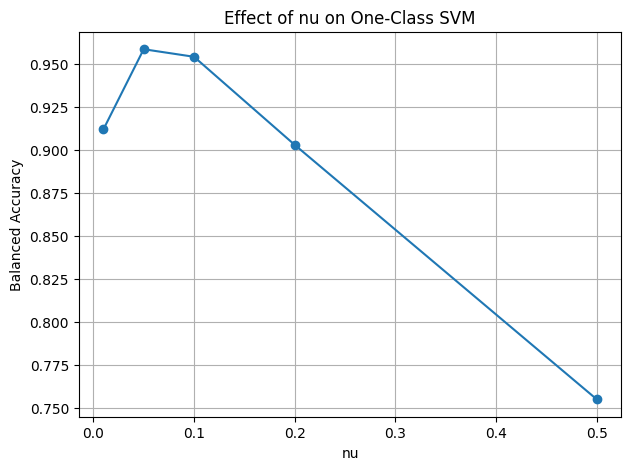

In [39]:
scale_results = results_df[
    results_df["gamma"] == "scale"
].sort_values("nu")

plt.figure(figsize=(7,5))
plt.plot(
    scale_results["nu"],
    scale_results["balanced_accuracy"],
    marker="o"
)

plt.xlabel("nu")
plt.ylabel("Balanced Accuracy")
plt.title("Effect of nu on One-Class SVM")
plt.grid()

plt.show()

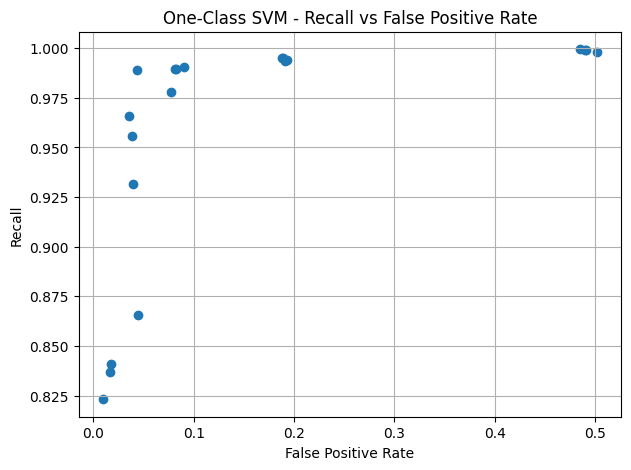

In [40]:
plt.figure(figsize=(7,5))

plt.scatter(
    results_df["fpr"],
    results_df["recall"]
)

plt.xlabel("False Positive Rate")
plt.ylabel("Recall")
plt.title("One-Class SVM - Recall vs False Positive Rate")
plt.grid()
plt.show()

In [41]:
best_nu = results_df.iloc[0]["nu"]
best_gamma = results_df.iloc[0]["gamma"]

print("Selected nu:", best_nu)
print("Selected gamma:", best_gamma)

Selected nu: 0.05
Selected gamma: 0.1


In [42]:
final_model = OneClassSVM(
    kernel="rbf",
    nu = best_nu,
    gamma = best_gamma
)

final_model.fit(X_train)

OneClassSVM(gamma=0.1, nu=np.float64(0.05))

In [43]:
test_predictions = final_model.predict(X_test)
test_predictions = (test_predictions == -1).astype(int)

test_cm = confusion_matrix(y_test, test_predictions)

tn,fp,fn,tp = test_cm.ravel()

print("Confusion Matrix:")
print(test_cm)

print("\nTrue Negaitves:", tn)
print("False Positives:", fp)
print("False Negaitves:", fn)
print("True Positives:", tp)

Confusion Matrix:
[[ 2262   141]
 [  518 52436]]

True Negaitves: 2262
False Positives: 141
False Negaitves: 518
True Positives: 52436


In [45]:
test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions)
test_recall = recall_score(y_test, test_predictions)
test_f1 = f1_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)

test_fpr = fp / (fp + tn)

test_scores = -final_model.decision_function(X_test)

test_roc_auc = roc_auc_score(y_test, test_scores)
test_pr_auc = average_precision_score(y_test, test_scores)

In [46]:
print("Accuracy:", test_accuracy)
print("Precision:", test_precision)
print("Recall:", test_recall)
print("F1-score:", test_f1)
print("Balanced Accuracy:", test_balanced_accuracy)
print("False Positive Rate:", test_fpr)
print("ROC-AUC:", test_roc_auc)
print("PR-AUC:", test_pr_auc)

Accuracy: 0.9880954531495565
Precision: 0.9973182189930958
Recall: 0.9902179249915021
F1-score: 0.9937553894116421
Balanced Accuracy: 0.9657706354046149
False Positive Rate: 0.05867665418227216
ROC-AUC: 0.9883311399080014
PR-AUC: 0.9993909197561642


In [47]:
attack_analysis = test_metadata.copy()
attack_analysis["Prediction"] = test_predictions

attack_analysis = attack_analysis[
    attack_analysis["Label"] == "Anomaly"
]

attack_detection = attack_analysis.groupby(
    "Attack_type"
)["Prediction"].agg(["count", "sum"])

attack_detection["detection_rate"] = (
    attack_detection["sum"] /
    attack_detection["count"]
)

attack_detection

,count,sum,detection_rate
Attack_type,,,
ARP_poisioning,3813,3300,0.865460
DDOS_Slowloris,266,266,1.000000
DOS_SYN_Hping,45045,45045,1.000000
Metasploit_Brute_Force_SSH,18,17,0.944444
NMAP_FIN_SCAN,14,13,0.928571
NMAP_OS_DETECTION,1000,1000,1.000000
NMAP_TCP_scan,501,501,1.000000
NMAP_UDP_SCAN,1292,1289,0.997678
NMAP_XMAS_TREE_SCAN,1005,1005,1.000000


In [49]:
results_df.to_csv(
    "../results/tables/one_class_svm_validation_results.csv",
    index=False
)

attack_detection.to_csv(
    "../results/tables/one_class_svm_attack_detection.csv"
)